In [ ]:
import pandas as pd
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_recall_curve

# 1. LOAD THE DATA 
print("Loading data...")
X_train = pd.read_csv('../data/X_train_resampled.csv')
y_train = pd.read_csv('../data/y_train_resampled.csv').values.ravel()
X_test = pd.read_csv('../data/X_test.csv')
y_test = pd.read_csv('../data/y_test.csv').values.ravel()

# 2. RETRAIN MODEL
print("Retraining LightGBM...")
best_model = LGBMClassifier(random_state=42, verbose=-1)
best_model.fit(X_train, y_train)

# 3. GET PROBABILITIES
y_proba = best_model.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

# 4. FIND THE SWEET SPOT (Max F1 Score)
# Calculate F1 score for every possible threshold
f1_scores = 2 * (precision * recall) / (precision + recall)
# Find the index of the highest F1 score
best_f1_idx = np.argmax(f1_scores)

# 5. THE RESULTS
print("\n" + "="*40)
print("OPTIMIZATION RESULTS")
print("="*40)
print(f"Best Balanced Threshold: {thresholds[best_f1_idx]:.4f}")
print(f"Recall at this threshold:    {recall[best_f1_idx]:.4f}  ({recall[best_f1_idx]*100:.1f}%)")
print(f"Precision at this threshold: {precision[best_f1_idx]:.4f}  ({precision[best_f1_idx]*100:.1f}%)")
print(f"F1 Score:                    {f1_scores[best_f1_idx]:.4f}")
print("="*40)

Loading data...
Retraining LightGBM...

OPTIMIZATION RESULTS
Best Balanced Threshold: 0.0344
Recall at this threshold:    0.3208  (32.1%)
Precision at this threshold: 0.0714  (7.1%)
F1 Score:                    0.1168


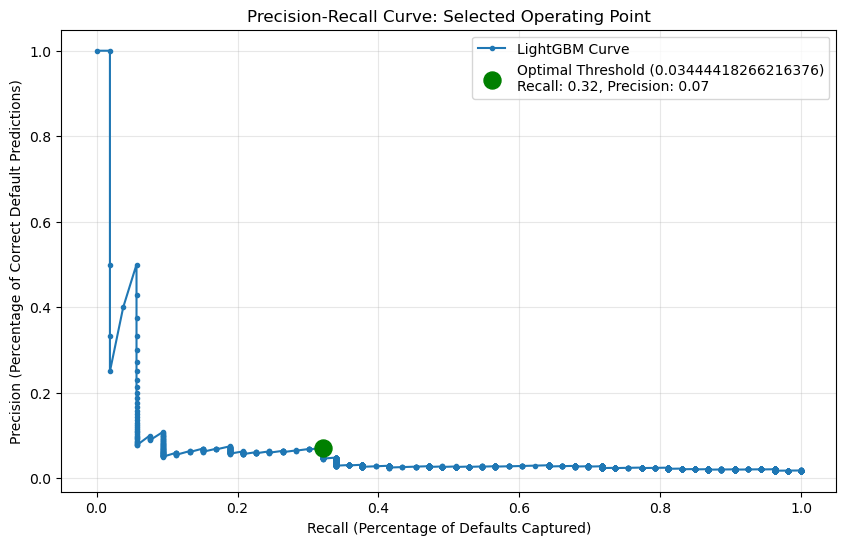

In [ ]:
import matplotlib.pyplot as plt
# 5. Plot the Curve
plt.figure(figsize=(10, 6))
plt.plot(recall, precision, marker='.', label='LightGBM Curve')

optimal_threshold = thresholds[best_f1_idx]
idx = np.argmin(np.abs(thresholds - optimal_threshold))

plt.scatter(recall[idx], precision[idx], marker='o', color='green', 
            label=f'Optimal Threshold ({optimal_threshold})\nRecall: {recall[idx]:.2f}, Precision: {precision[idx]:.2f}', 
            s=150, zorder=5)

plt.title('Precision-Recall Curve: Selected Operating Point')
plt.xlabel('Recall (Percentage of Defaults Captured)')
plt.ylabel('Precision (Percentage of Correct Default Predictions)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig('../plots/final_figure_pr_curve_optimized.png')
plt.show()